We will implement a simple ANN to solve simple classification problems

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import make_blobs, make_circles, make_moons
from sklearn.model_selection import train_test_split

In [14]:
class ANN(nn.Module):
    def __init__(self, n_in, n_hidden, n_out):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, n_hidden), nn.ReLU(),
            nn.Linear(n_hidden, n_hidden), nn.ReLU(),
            nn.Linear(n_hidden, n_out),
        )

    def forward(self, x):
        return self.net(x)

In [4]:
def make_spirals(n=500, noise=0.1):
    t = np.sqrt(np.random.rand(n // 2)) * 2 * np.pi
    x1 = t * np.cos(t) + np.random.randn(n // 2) * noise
    y1 = t * np.sin(t) + np.random.randn(n // 2) * noise
    x2 = -t * np.cos(t) + np.random.randn(n // 2) * noise
    y2 = -t * np.sin(t) + np.random.randn(n // 2) * noise
    X = np.vstack([np.c_[x1, y1], np.c_[x2, y2]])
    y = np.array([0] * (n // 2) + [1] * (n // 2))
    return X, y

def make_xor(n=500, noise=0.1):
    pts = [(0, 0, 0), (1, 1, 0), (0, 1, 1), (1, 0, 1)]
    X, y = [], []
    for cx, cy, label in pts:
        X.append(np.random.randn(n // 4, 2) * noise + [cx, cy])
        y += [label] * (n // 4)
    return np.vstack(X), np.array(y)

def get_data(name, cluster_std=2.5, noise=0.3, factor=0.3):
    if name == "blobs_2":
        return make_blobs(n_samples=500, centers=2, cluster_std=cluster_std, random_state=42)
    if name == "blobs_3":
        return make_blobs(n_samples=500, centers=3, cluster_std=cluster_std, random_state=42)
    if name == "circles":
        return make_circles(n_samples=500, noise=noise, factor=factor, random_state=42)
    if name == "moons":
        return make_moons(n_samples=500, noise=noise, random_state=42)
    if name == "spirals":
        return make_spirals(noise=noise)
    if name == "xor":
        return make_xor(noise=noise)
    raise ValueError(name)

def plot_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 150), np.linspace(y_min, y_max, 150))
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
    with torch.no_grad():
        Z = model(grid).argmax(1).numpy().reshape(xx.shape)
    plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k", s=15)
    plt.title(title)

In [5]:
def train(dataset="circles", epochs=300, lr=1e-3, patience=30, n_hidden=32, **kwargs):
    X, y = get_data(dataset, **kwargs)
    X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42)
    X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

    X_train = torch.tensor(X_train, dtype=torch.float32)
    y_train = torch.tensor(y_train, dtype=torch.long)
    X_val = torch.tensor(X_val, dtype=torch.float32)
    y_val = torch.tensor(y_val, dtype=torch.long)
    X_test = torch.tensor(X_test, dtype=torch.float32)
    y_test = torch.tensor(y_test, dtype=torch.long)

    model = ANN(2, n_hidden=n_hidden, n_out=len(np.unique(y)))
    opt = optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    train_losses, val_losses = [], []
    best_val, best_state, wait = float("inf"), None, 0
    stopped_early = False

    for epoch in range(epochs):
        model.train()
        opt.zero_grad()
        train_loss = loss_fn(model(X_train), y_train)
        train_loss.backward()
        opt.step()
        train_losses.append(train_loss.item())

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(X_val), y_val).item()
        val_losses.append(val_loss)

        if val_loss < best_val:
            best_val = val_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                stopped_early = True
                print(f"Early stopping at epoch {epoch + 1} (best val loss={best_val:.4f})")
                break

        if (epoch + 1) % 100 == 0:
            model.eval()
            with torch.no_grad():
                val_acc = (model(X_val).argmax(1) == y_val).float().mean()
            print(
                f"Epoch {epoch + 1}: train={train_losses[-1]:.4f}  "
                f"val={val_losses[-1]:.4f}  val_acc={val_acc:.2%}"
            )

    model.load_state_dict(best_state)
    with torch.no_grad():
        test_loss = loss_fn(model(X_test), y_test).item()
        test_acc = (model(X_test).argmax(1) == y_test).float().mean()
    print(f"{dataset} test loss={test_loss:.4f}  test acc={test_acc:.2%}")

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].plot(train_losses, label="Train")
    axes[0].plot(val_losses, label="Validation")
    if stopped_early:
        axes[0].axvline(len(train_losses) - 1, color="gray", ls="--", label="Early stop")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_title(f"{dataset} — loss (test acc={test_acc:.0%})")
    axes[0].legend()

    plt.sca(axes[1])
    plot_boundary(model, X, y, f"{dataset} (test {test_acc:.0%})")
    plt.tight_layout()
    plt.show()


In [6]:
datasets = {
        "blobs_2": {"cluster_std": 2.5},
        "blobs_3": {"cluster_std": 2.5},
        "circles": {"noise": 0.25, "factor": 0.3},
        "moons": {"noise": 0.35},
        "spirals": {"noise": 0.25},
        "xor": {"noise": 0.3},
    }

Epoch 100: train=0.1060  val=0.0829  val_acc=99.00%
Epoch 200: train=0.0790  val=0.0564  val_acc=99.00%
Early stopping at epoch 290 (best val loss=0.0530)
blobs_2 test loss=0.0605  test acc=99.00%


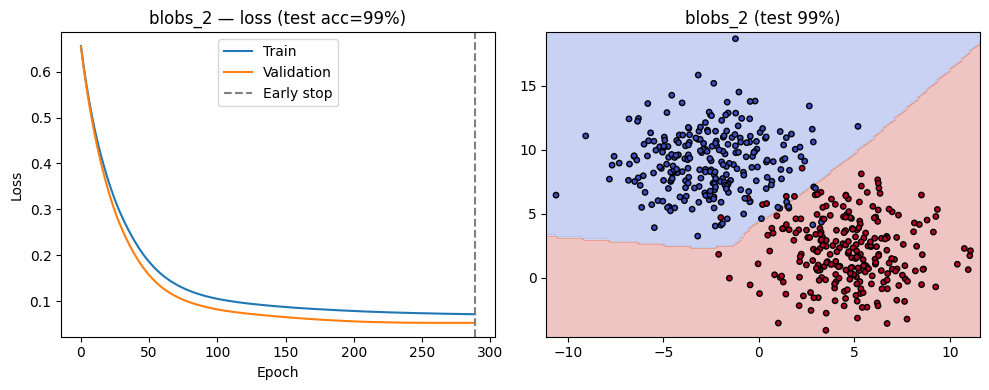

Epoch 100: train=0.1063  val=0.0689  val_acc=97.00%
Epoch 200: train=0.0651  val=0.0401  val_acc=98.00%
Epoch 300: train=0.0502  val=0.0303  val_acc=98.00%
blobs_3 test loss=0.0836  test acc=97.00%


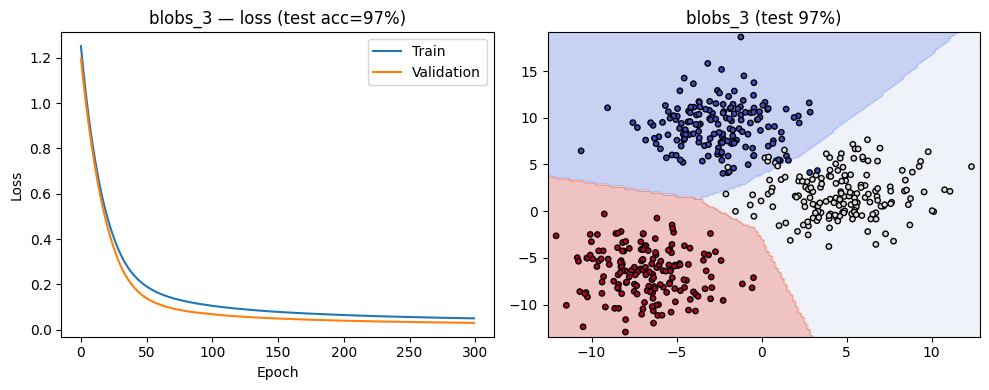

Epoch 100: train=0.3909  val=0.3881  val_acc=89.00%
Epoch 200: train=0.2518  val=0.2654  val_acc=90.00%
Early stopping at epoch 228 (best val loss=0.2653)
circles test loss=0.2598  test acc=92.00%


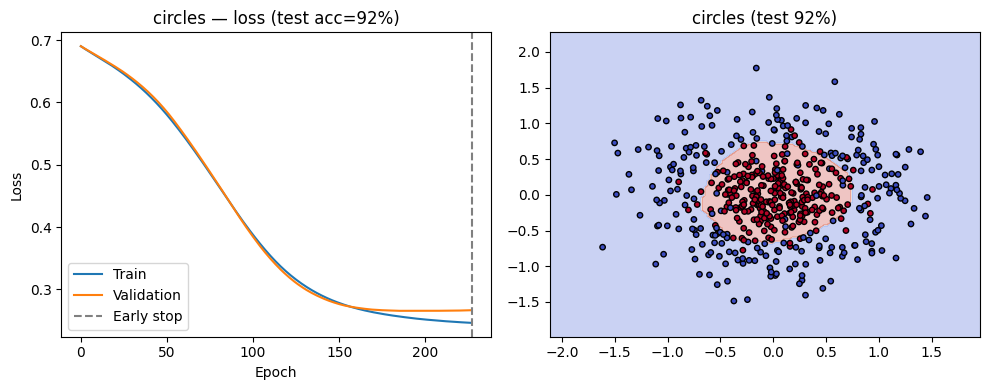

Epoch 100: train=0.3293  val=0.3389  val_acc=86.00%
Epoch 200: train=0.2626  val=0.2852  val_acc=83.00%
Epoch 300: train=0.2268  val=0.2719  val_acc=85.00%
moons test loss=0.3048  test acc=86.00%


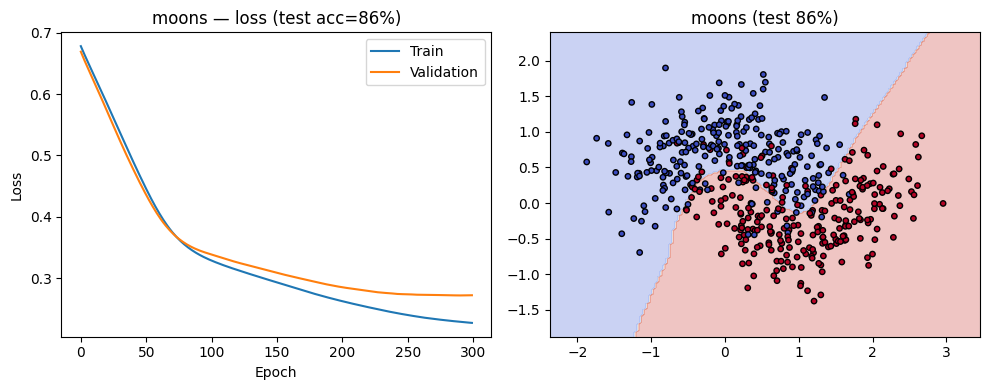

Epoch 100: train=0.2605  val=0.2113  val_acc=87.00%
Epoch 200: train=0.0459  val=0.0426  val_acc=99.00%
Epoch 300: train=0.0151  val=0.0150  val_acc=100.00%
spirals test loss=0.0168  test acc=100.00%


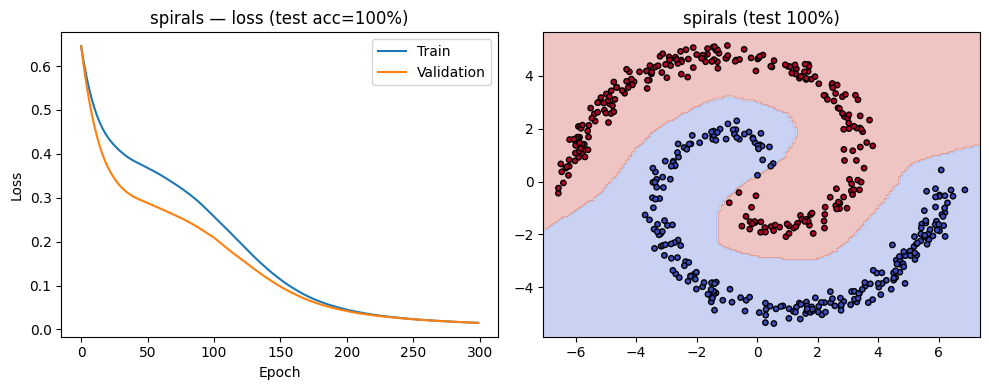

Epoch 100: train=0.3674  val=0.3754  val_acc=90.00%
Epoch 200: train=0.2037  val=0.2605  val_acc=89.00%
Early stopping at epoch 215 (best val loss=0.2596)
xor test loss=0.3291  test acc=86.00%


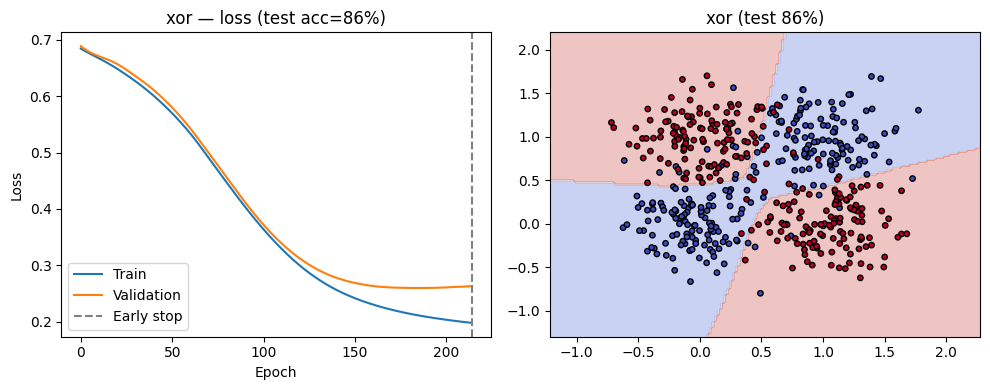

In [15]:
for name, kwargs in datasets.items():
    train(name, **kwargs)

In most cases, validation loss continued to drop even after 300 epochs suggesting no overfit to training set. In some datasets, early stopping occured (blobs_2, circles and xor) due to increase in validation loss.

let's change the hidden dim to 16

Epoch 100: train=0.1682  val=0.1396  val_acc=97.00%
Epoch 200: train=0.0980  val=0.0678  val_acc=97.00%
Epoch 300: train=0.0890  val=0.0589  val_acc=98.00%
blobs_2 test loss=0.0714  test acc=97.00%


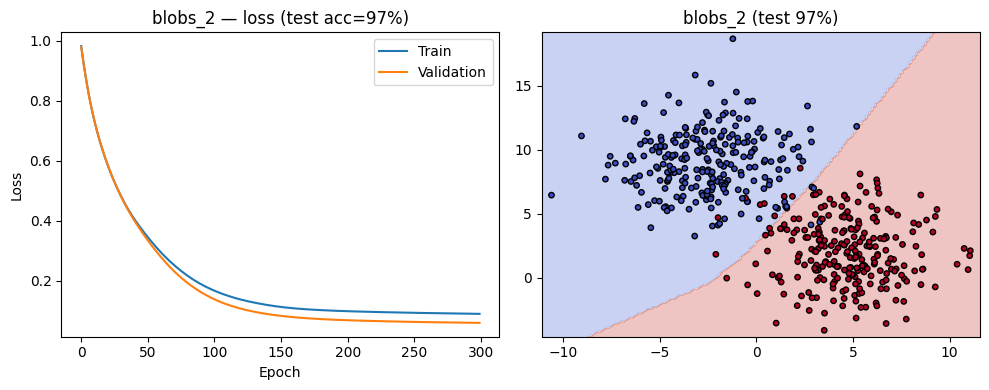

Epoch 100: train=0.2814  val=0.2364  val_acc=96.00%
Epoch 200: train=0.1090  val=0.0787  val_acc=97.00%
Epoch 300: train=0.0837  val=0.0573  val_acc=97.00%
blobs_3 test loss=0.1116  test acc=97.00%


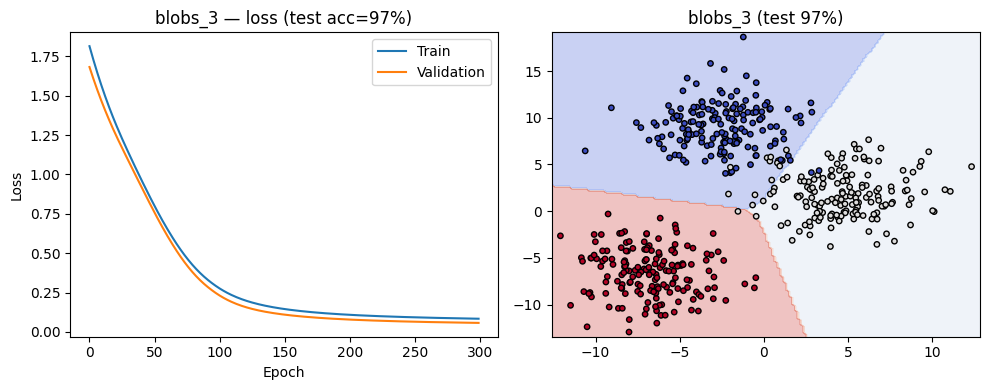

Epoch 100: train=0.5930  val=0.5916  val_acc=82.00%
Epoch 200: train=0.3190  val=0.3299  val_acc=88.00%
Epoch 300: train=0.2466  val=0.2668  val_acc=90.00%
circles test loss=0.2647  test acc=90.00%


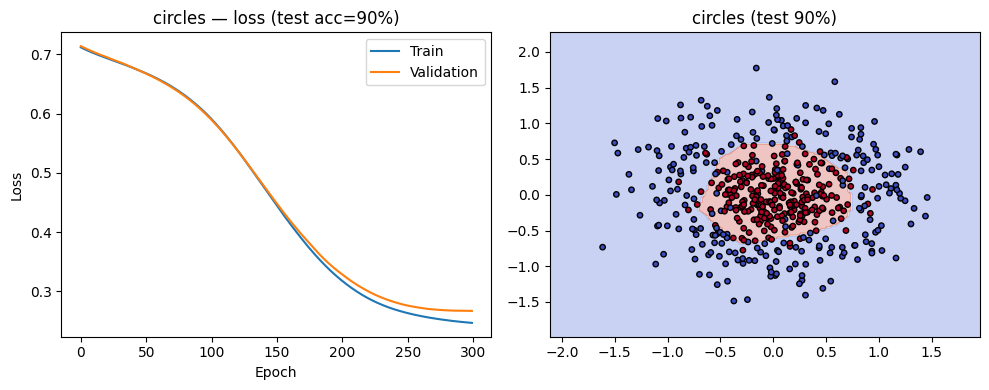

Epoch 100: train=0.4164  val=0.4056  val_acc=84.00%
Epoch 200: train=0.3381  val=0.3314  val_acc=86.00%
Epoch 300: train=0.3115  val=0.3194  val_acc=85.00%
moons test loss=0.3308  test acc=86.00%


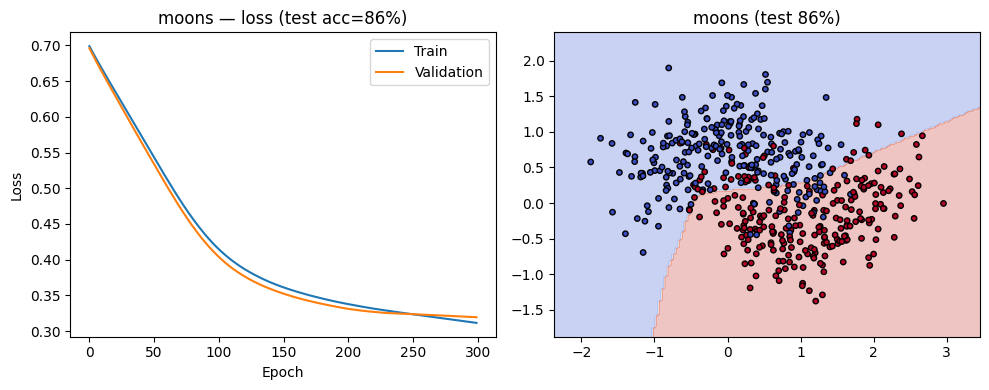

Epoch 100: train=0.4457  val=0.4906  val_acc=71.00%
Epoch 200: train=0.3186  val=0.3492  val_acc=72.00%
Epoch 300: train=0.1724  val=0.1803  val_acc=100.00%
spirals test loss=0.1664  test acc=99.00%


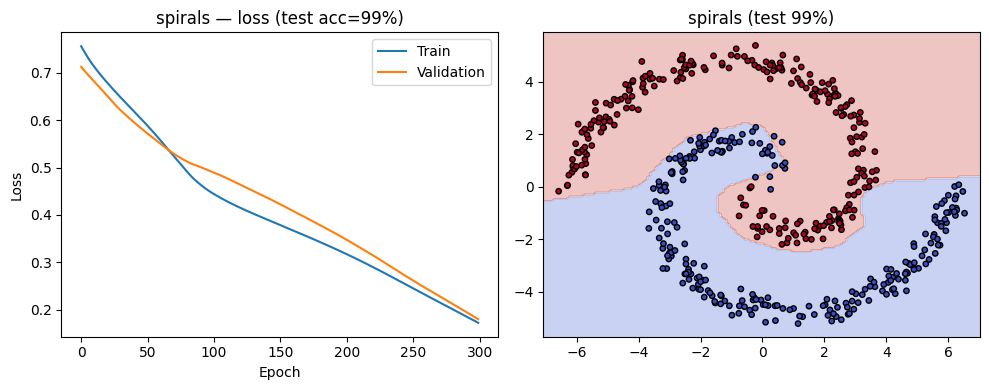

Epoch 100: train=0.5788  val=0.5817  val_acc=86.00%
Epoch 200: train=0.3850  val=0.3530  val_acc=87.00%
Epoch 300: train=0.2884  val=0.2486  val_acc=87.00%
xor test loss=0.2754  test acc=92.00%


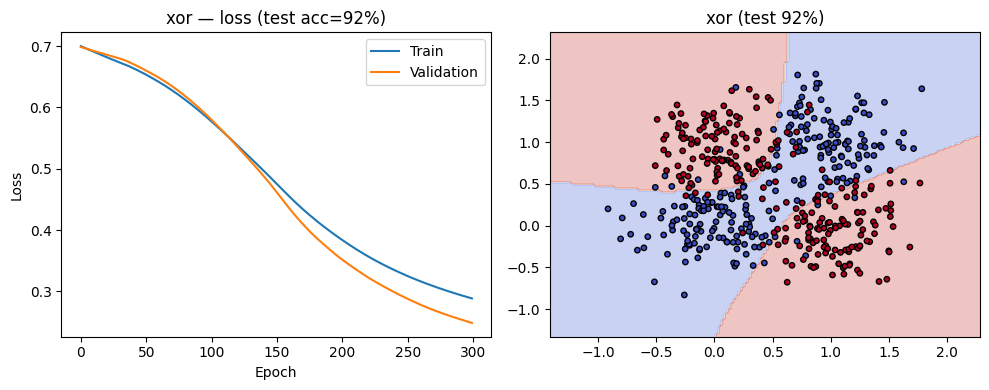

In [16]:
for name, kwargs in datasets.items():
    train(name, n_hidden=16, **kwargs)

Of course, lowering the hidden dimension resulted in poorer test accuracy except for xor dataset, suggesting that maybe 32 hidden dim is too much (overfit).